# Molecular graph model and training

Real ORD inputs, readable selected GINE definitions, actual grouped validation and final training histories. The saved run is identified explicitly; viewing the notebook does not retrain or rescore tests.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Selected graph and GINE model
The retained model uses the original 11 atom features and role-aware pooling. These are its production graph/model definitions, not a random replacement. Constant names are aliased only so both feature versions can coexist in one notebook kernel. The trained checkpoint replay below verifies equivalence. Source hashes: graph `a435e84c1e6ba1d86d077133d89abb64d5b3bd79131d221391f03f189e568af4`, model `b08de1ef91832bbad7f268c25425e4650acacae7b2646107848c1146092090de`.

In [2]:
import math
import torch
from torch_geometric.data import Data
from reaction_gnn.data import canonical

NODE_DIM=11
EDGE_DIM=4

def reaction_graph(record):
    nodes=[];edges=[];bonds=[]
    for component in record["components"]:
        role=component["role"]
        if role not in range(4): raise ValueError("Input role must be 0..3")
        _,mol=canonical(component["smiles"]);offset=len(nodes)
        for atom in mol.GetAtoms():
            features=[atom.GetAtomicNum()/100,atom.GetDegree()/4,atom.GetFormalCharge()/4,atom.GetTotalNumHs()/4,float(atom.GetIsAromatic()),float(atom.IsInRing()),atom.GetMass()/200]+[float(role==i) for i in range(4)]
            nodes.append(features)
        for bond in mol.GetBonds():
            a,b=bond.GetBeginAtomIdx()+offset,bond.GetEndAtomIdx()+offset
            attributes=[bond.GetBondTypeAsDouble()/3,float(bond.GetIsConjugated()),float(bond.IsInRing()),float(bond.GetIsAromatic())]
            edges.extend([(a,b),(b,a)]);bonds.extend([attributes,attributes])
    if not nodes: raise ValueError("Empty reaction graph")
    temperature=record.get("temperature_c")
    if temperature is not None and not math.isfinite(float(temperature)):
        raise ValueError("temperature_c must be finite or null")
    graph=Data(x=torch.tensor(nodes,dtype=torch.float32),edge_index=torch.tensor(edges,dtype=torch.long).t().contiguous() if edges else torch.empty((2,0),dtype=torch.long),edge_attr=torch.tensor(bonds,dtype=torch.float32).reshape(-1,EDGE_DIM),conditions=torch.tensor([[temperature/100 if temperature is not None else 0.,float(temperature is None)]],dtype=torch.float32))
    if "yield_percent" in record: graph.y=torch.tensor([record["yield_percent"]/100],dtype=torch.float32)
    return graph

legacy_reaction_graph = reaction_graph


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
import torch
from torch import nn
from torch_geometric.nn import GINEConv,global_mean_pool
from reaction_gnn.graph import NODE_DIM as LEGACY_NODE_DIM, EDGE_DIM as LEGACY_EDGE_DIM

class YieldGNN(nn.Module):
    def __init__(self,hidden=48,layers=3,pooling="global",dropout=0.):
        super().__init__();self.hidden=hidden;self.layers=layers;self.pooling=pooling;self.dropout=dropout
        self.encoder=nn.Linear(LEGACY_NODE_DIM,hidden)
        self.convs=nn.ModuleList([GINEConv(nn.Sequential(nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,hidden)),edge_dim=LEGACY_EDGE_DIM) for _ in range(layers)])
        self.head=nn.Sequential(nn.Linear(hidden*(4 if pooling=="role" else 1)+2,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,1))
    def forward(self,batch):
        x=torch.relu(self.encoder(batch.x))
        for conv in self.convs: x=torch.relu(conv(x,batch.edge_index,batch.edge_attr)+x)
        if self.pooling=="role":
            # Distinguish substrates/reagents/solvents/catalysts instead of diluting them.
            roles=batch.x[:,7:11].argmax(1);pooled=[]
            for role in range(4):
                selected=roles==role
                pooled.append(global_mean_pool(x[selected],batch.batch[selected],size=batch.num_graphs))
            pooled=torch.cat(pooled,dim=1)
        else: pooled=global_mean_pool(x,batch.batch)
        return torch.sigmoid(self.head(torch.cat([pooled,batch.conditions],dim=1))).flatten()


In [4]:
from copy import deepcopy
from torch_geometric.loader import DataLoader
from reaction_gnn.train import metrics

### Visible production core: `src/reaction_gnn/quantity_study.py`

These readable definitions are copied from the executed production module (SHA256 `45d96b68b3016bbe7a08379b989184c0a7c35c341141b5b32ce105f2a0202eed`). They expose the algorithm directly; optional full studies still use production entrypoints and fresh outputs. No hidden source execution or encoded bootstrap is used. The inline model factory is restricted to the selected version-1 GNN; the training loop is unchanged.

In [5]:
def loader(graphs,version,batch_size=32,shuffle=False,seed=42):
    return DataLoader(graphs,batch_size=batch_size,shuffle=shuffle,generator=torch.Generator().manual_seed(seed),follow_batch=['component_roles'] if version==2 else [])


def predictions(model,graphs,version):
    model.eval()
    with torch.no_grad():values=torch.cat([model(batch) for batch in loader(graphs,version)]).numpy()*100
    if not np.isfinite(values).all() or (values<0).any() or (values>100).any():raise ValueError('Invalid model forecasts')
    return values


def model_for(config,fixed):
    assert config['feature_version']==1
    cls=YieldGNN
    return cls(fixed['hidden'],fixed['layers'],config['pooling'],fixed['dropout'])


def fit_graph(graphs,validation,config,fixed,seed,epochs=None):
    torch.manual_seed(seed);model=model_for(config,fixed)
    optimizer=torch.optim.AdamW(model.parameters(),lr=fixed['lr'],weight_decay=fixed['weight_decay'])
    batches=loader(graphs,config['feature_version'],fixed['batch_size'],True,seed)
    history=[];best=float('inf');state=None;best_epoch=0
    maximum=epochs if epochs is not None else fixed['max_epochs']
    for epoch in range(maximum):
        model.train();total=0.;maximum_gradient=0.
        for batch in batches:
            output=model(batch)
            loss=torch.nn.functional.mse_loss(output,batch.y) if config['loss']=='mse' else torch.nn.functional.smooth_l1_loss(output,batch.y,beta=config['beta'])
            if not bool(torch.isfinite(loss)):raise ValueError('Nonfinite training loss')
            optimizer.zero_grad();loss.backward()
            norm=torch.nn.utils.clip_grad_norm_(model.parameters(),5.,error_if_nonfinite=True)
            maximum_gradient=max(maximum_gradient,float(norm));optimizer.step();total+=float(loss.detach())*batch.num_graphs
        item={'epoch':epoch+1,'train_loss_fraction':total/len(graphs),'maximum_gradient_norm_before_clip':maximum_gradient}
        if validation is not None:
            graph_val,target=validation;score=metrics(target,predictions(model,graph_val,config['feature_version']))['mae_percentage_points'];item['validation_mae']=score
            if score<best:best=score;state=deepcopy(model.state_dict());best_epoch=epoch+1
        history.append(item)
        if validation is not None and epoch+1>=fixed['minimum_epochs'] and epoch+1-best_epoch>=fixed['early_stopping_patience']:break
    if validation is not None:
        if state is None:raise ValueError('No finite validation checkpoint')
        model.load_state_dict(state)
    return model,best_epoch if validation is not None else maximum,history


def save_model(model,config,fixed,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    torch.save({'state_dict':model.state_dict(),'hidden':fixed['hidden'],'layers':fixed['layers'],'pooling':config['pooling'],'dropout':fixed['dropout'],'feature_version':config['feature_version']},path)


def select_gnn(trials):
    baseline=next(t for t in trials if t['config']['feature_version']==1)
    eligible=[baseline]
    for t in trials:
        if t is baseline:continue
        wins=sum(x<y for x,y in zip(t['fold_validation_mae'],baseline['fold_validation_mae']))
        if t['mean_validation_mae']<=baseline['mean_validation_mae']-.5 and wins>=2:eligible.append(t)
    return min(eligible,key=lambda t:t['mean_validation_mae'])


## Grouped validation
The selected configuration uses three principal-reactant-scaffold folds on all 610 development records. These are recorded validation results; no test labels enter configuration selection.

In [6]:
selection=read_json('docs/selected-run.json')
folds=pd.DataFrame({'fold':range(3),'validation_mae_pp':selection['fold_validation_mae'],'best_epoch':selection['best_epochs']})
display(folds)
print('Mean grouped validation MAE:',folds.validation_mae_pp.mean())
print('Development records: 610; reserved observed ELN records: 130')
print('Selected configuration:',selection['config'])


,fold,validation_mae_pp,best_epoch
0,0,23.589201,56
1,1,24.182208,4
2,2,22.928919,47


Mean grouped validation MAE: 23.566776075518305
Development records: 610; reserved observed ELN records: 130
Selected configuration: {'name': 'legacy_role48', 'feature_version': 1, 'pooling': 'role', 'loss': 'mse'}


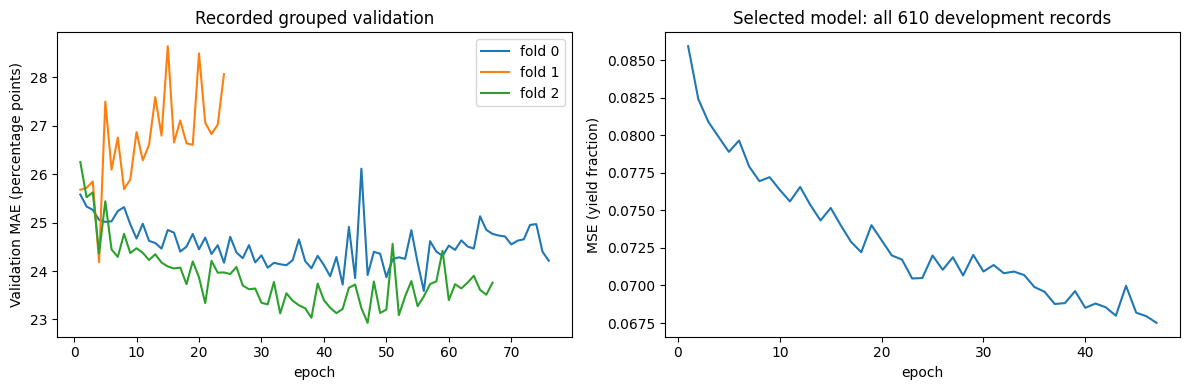

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for i,recorded in enumerate(selection['fold_history']):
    history=pd.DataFrame(recorded)
    axes[0].plot(history.epoch,history.validation_mae,label=f'fold {i}')
final=pd.DataFrame(selection['final_training_history'])
axes[1].plot(final.epoch,final.train_loss_fraction,color='tab:blue')
axes[0].set(xlabel='epoch',ylabel='Validation MAE (percentage points)',title='Recorded grouped validation')
axes[1].set(xlabel='epoch',ylabel='MSE (yield fraction)',title='Selected model: all 610 development records')
axes[0].legend();fig.tight_layout();fig.savefig(ROOT/'docs/figures/reaction_actual_training_curves.png',dpi=150);plt.show()


## Optional full training
Visible loop definitions above are executable. Full production study is opt-in, uses real prepared data and creates fresh artifacts. It never scores the historically observed ELN holdout.

In [8]:
RUN_TRAIN=False
if RUN_TRAIN:
    import subprocess
    from datetime import datetime,timezone
    output='models/notebook-selected-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    subprocess.run([sys.executable,'train.py','--output',output],check=True)
else:
    print('Training disabled. Recorded run shown above; enable explicitly for a fresh development-only refit.')


Training disabled. Recorded run shown above; enable explicitly for a fresh development-only refit.


## Recorded training identity and retained checkpoint
The curves above are recorded fold histories. This cell shows the exact configuration/environment and frozen release identity; no training is performed here.

In [9]:
print('Selected training config:',read_json('docs/selected-model.json')['training'])
print('Recorded environment:',selection['environment'])
print('Final epochs:',selection['epochs'])
print('Retained checkpoint SHA256:',selection['checkpoint_sha256'])


Selected training config: {'hidden': 48, 'layers': 3, 'lr': 0.003, 'weight_decay': 0.0001, 'dropout': 0.0, 'batch_size': 24, 'max_epochs': 120, 'minimum_epochs': 20, 'early_stopping_patience': 20, 'seeds': '42+fold for fitting;42 for final refit', 'threads': 2, 'device': 'cpu'}
Recorded environment: {'python': '3.14.2', 'torch': '2.14.0+cpu', 'threads': 2, 'device': 'cpu', 'packages': {'torch-geometric': '2.8.1', 'rdkit': '2026.3.6', 'numpy': '2.4.2', 'scikit-learn': '1.8.0', 'ord-schema': '0.9.3', 'pyarrow': '25.0.1'}}
Final epochs: 47
Retained checkpoint SHA256: a23bf986ffaa53d6003dd6648f98141b697438c790c9bb8ebc60adab50ec2e97


## Run the visible selected class with actual learned weights
This loads the frozen trained state into the inline class above and compares its public-example forecast with production inference. No training or test scoring occurs; the equality checks architecture/feature consistency.

In [10]:
from torch_geometric.data import Batch
from reaction_gnn.train import load_model,predict_record
production=load_model('models/loss-v4/selected.pt')
inline=YieldGNN(production.hidden,production.layers,production.pooling,production.dropout)
inline.load_state_dict(production.state_dict())
inline.eval()
example={'components':[{'smiles':'Brc1ccccc1','role':0},{'smiles':'Nc1ccccc1','role':0},{'smiles':'CCO','role':2}],'temperature_c':80.}
with torch.no_grad():
    inline_value=float(inline(Batch.from_data_list([legacy_reaction_graph(example)]))[0])*100
production_value=predict_record(production,example)
assert abs(inline_value-production_value)<1e-7
print('Inline trained GNN example yield (%):',inline_value)
print('Difference from production inference:',abs(inline_value-production_value))

Inline trained GNN example yield (%): 28.50843071937561
Difference from production inference: 0.0
